<a href="https://colab.research.google.com/github/GuldenizKendigelen/Flight-Delays-Cancellations-Analysis-2019-2023-/blob/main/notebooks/flight_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PROJENİN AMACI

Bir uçuşun **iptal edilip edilmeyeceğini** önceden tahmin etmek.

Bu amaçla geçmiş uçuş verileri kullanılarak bir **sınıflandırma modeli** oluşturulmuştur.

**Hedef:**
- 0 → İptal değil
- 1 → İptal

Modellerin performansı karşılaştırılarak en uygun model seçilmiştir.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

In [ ]:
FILE_PATH = "flights_sample_3m.csv"

df = pd.read_csv(FILE_PATH, low_memory=False)

# Sütun adlarını standartlaştır
df.columns = df.columns.str.strip().str.upper()

print("Satır sayısı:", len(df))
print("Sütun sayısı:", len(df.columns))

display(df.head())
print("Sütunlar:", df.columns.tolist())

Satır sayısı: 3000000
Sütun sayısı: 32


,FL_DATE,AIRLINE,AIRLINE_DOT,AIRLINE_CODE,DOT_CODE,FL_NUMBER,ORIGIN,ORIGIN_CITY,DEST,DEST_CITY,...,DIVERTED,CRS_ELAPSED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,2019-01-09,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,1562,FLL,"Fort Lauderdale, FL",EWR,"Newark, NJ",...,0.0,186.0,176.0,153.0,1065.0,NaN,NaN,NaN,NaN,NaN
1,2022-11-19,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,1149,MSP,"Minneapolis, MN",SEA,"Seattle, WA",...,0.0,235.0,236.0,189.0,1399.0,NaN,NaN,NaN,NaN,NaN
2,2022-07-22,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,459,DEN,"Denver, CO",MSP,"Minneapolis, MN",...,0.0,118.0,112.0,87.0,680.0,NaN,NaN,NaN,NaN,NaN
3,2023-03-06,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,2295,MSP,"Minneapolis, MN",SFO,"San Francisco, CA",...,0.0,260.0,285.0,249.0,1589.0,0.0,0.0,24.0,0.0,0.0
4,2020-02-23,Spirit Air Lines,Spirit Air Lines: NK,NK,20416,407,MCO,"Orlando, FL",DFW,"Dallas/Fort Worth, TX",...,0.0,181.0,182.0,153.0,985.0,NaN,NaN,NaN,NaN,NaN


Sütunlar: ['FL_DATE', 'AIRLINE', 'AIRLINE_DOT', 'AIRLINE_CODE', 'DOT_CODE', 'FL_NUMBER', 'ORIGIN', 'ORIGIN_CITY', 'DEST', 'DEST_CITY', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'DELAY_DUE_CARRIER', 'DELAY_DUE_WEATHER', 'DELAY_DUE_NAS', 'DELAY_DUE_SECURITY', 'DELAY_DUE_LATE_AIRCRAFT']


In [ ]:
print("Eksik değerler:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nTekrarlanan satır:", df.duplicated().sum())

print("\nVeri tipleri:")
display(df.dtypes)

Eksik değerler:


,0
CANCELLATION_CODE,2920860
DELAY_DUE_LATE_AIRCRAFT,2466137
DELAY_DUE_CARRIER,2466137
DELAY_DUE_SECURITY,2466137
DELAY_DUE_NAS,2466137
DELAY_DUE_WEATHER,2466137
ARR_DELAY,86198
ELAPSED_TIME,86198
AIR_TIME,86198
WHEELS_ON,79944



Tekrarlanan satır: 0

Veri tipleri:


,0
FL_DATE,object
AIRLINE,object
AIRLINE_DOT,object
AIRLINE_CODE,object
DOT_CODE,int64
FL_NUMBER,int64
ORIGIN,object
ORIGIN_CITY,object
DEST,object
DEST_CITY,object


In [ ]:
df["CANCELLED"] = pd.to_numeric(df["CANCELLED"], errors="coerce")

df = df.dropna(subset=["CANCELLED"]).copy()

df["CANCELLED"] = df["CANCELLED"].astype(int)

print(df["CANCELLED"].value_counts())
print(df["CANCELLED"].value_counts(normalize=True))

CANCELLED
0    2920860
1      79140
Name: count, dtype: int64
CANCELLED
0    0.97362
1    0.02638
Name: proportion, dtype: float64


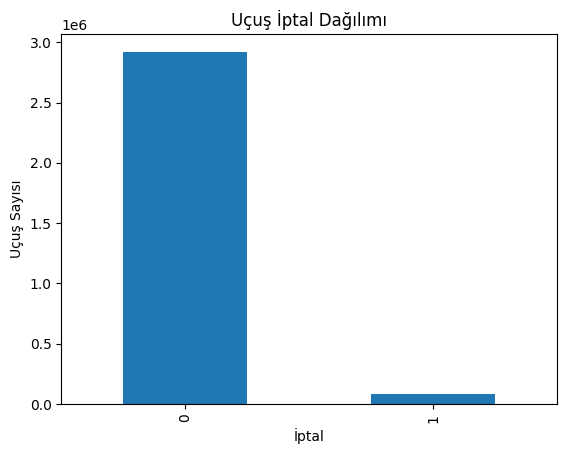

In [ ]:
df["CANCELLED"].value_counts().plot(kind="bar")

plt.title("Uçuş İptal Dağılımı")
plt.xlabel("İptal")
plt.ylabel("Uçuş Sayısı")
plt.show()

In [ ]:
print("İptal oranı: %", round(df["CANCELLED"].mean() * 100, 2))

İptal oranı: % 2.64


Burada uçuş iptal olmadan önce bilinebilecek değişkenleri kullanıyoruz.

In [ ]:
features = [
    "MONTH",
    "DAY_OF_WEEK",
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "DISTANCE"
]

features = [col for col in features if col in df.columns]

X = df[features].copy()
y = df["CANCELLED"]

print("Kullanılan özellikler:")
print(features)

Kullanılan özellikler:
['AIRLINE', 'DISTANCE']


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 2100000
Validation: 450000
Test: 450000


In [ ]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

Logistic Regression

In [ ]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['DISTANCE']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['AIRLINE'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

Random Forest

In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['DISTANCE']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['AIRLINE'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])

In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("F1", ascending=False).round(3)
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,Random Forest,0.591,0.037,0.584,0.070,0.618
0,Logistic Regression,0.511,0.033,0.621,0.063,0.586


İptal edilen uçuşlar genellikle azınlıkta olduğu için sadece accuracy'ye bakmak yeterli değildir.

In [ ]:
best_model = rf_model

val_prob = best_model.predict_proba(X_val)[:, 1]

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:

    val_pred = (val_prob >= threshold).astype(int)

    print(
        f"Threshold {threshold}: "
        f"Precision={precision_score(y_val, val_pred, zero_division=0):.3f}, "
        f"Recall={recall_score(y_val, val_pred, zero_division=0):.3f}, "
        f"F1={f1_score(y_val, val_pred, zero_division=0):.3f}"
    )

Threshold 0.3: Precision=0.029, Recall=0.915, F1=0.056
Threshold 0.4: Precision=0.032, Recall=0.798, F1=0.062
Threshold 0.5: Precision=0.037, Recall=0.584, F1=0.070
Threshold 0.6: Precision=0.045, Recall=0.280, F1=0.077
Threshold 0.7: Precision=0.063, Recall=0.055, F1=0.059


In [ ]:
thresholds = np.arange(0.10, 0.91, 0.05)

scores = []

for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)
    scores.append(f1_score(y_val, pred, zero_division=0))

best_threshold = thresholds[np.argmax(scores)]

print("Seçilen threshold:", best_threshold)
print("Validation F1:", max(scores))

Seçilen threshold: 0.6000000000000002
Validation F1: 0.07685115715357535


In [ ]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, test_pred, zero_division=0))

Accuracy: 0.8223
Precision: 0.0435
Recall: 0.2734
F1: 0.0751
ROC-AUC: 0.6136

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.84      0.90    438129
           1       0.04      0.27      0.08     11871

    accuracy                           0.82    450000
   macro avg       0.51      0.56      0.49    450000
weighted avg       0.95      0.82      0.88    450000



In [ ]:
cm = confusion_matrix(y_test, test_pred)

print(cm)

[[366796  71333]
 [  8626   3245]]


Random Forest için:

In [ ]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

importance = best_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

,Feature,Importance
0,num__DISTANCE,0.814723
4,cat__AIRLINE_Delta Air Lines Inc.,0.064482
16,cat__AIRLINE_Southwest Airlines Co.,0.028764
2,cat__AIRLINE_Allegiant Air,0.015353
15,cat__AIRLINE_SkyWest Airlines Inc.,0.011076
7,cat__AIRLINE_ExpressJet Airlines LLC d/b/a aha!,0.010563
9,cat__AIRLINE_Hawaiian Airlines Inc.,0.009360
18,cat__AIRLINE_United Air Lines Inc.,0.005494
5,cat__AIRLINE_Endeavor Air Inc.,0.005403
14,cat__AIRLINE_Republic Airline,0.005304


In [ ]:
sample = X_test.head(10).copy()

sample_prob = best_model.predict_proba(sample)[:, 1]
sample_pred = (sample_prob >= best_threshold).astype(int)

sample["IPTAL_OLASILIGI"] = (sample_prob * 100).round(2)
sample["TAHMIN"] = np.where(
    sample_pred == 1,
    "İptal",
    "İptal değil"
)

display(sample)

,AIRLINE,DISTANCE,IPTAL_OLASILIGI,TAHMIN
2930724,Endeavor Air Inc.,888.0,70.48,İptal
805601,PSA Airlines Inc.,386.0,44.94,İptal değil
989232,JetBlue Airways,680.0,34.72,İptal değil
1513264,Southwest Airlines Co.,853.0,57.36,İptal değil
904821,American Airlines Inc.,175.0,63.85,İptal
1368855,Southwest Airlines Co.,986.0,40.30,İptal değil
1095798,American Airlines Inc.,2343.0,20.55,İptal değil
1787466,Southwest Airlines Co.,363.0,64.99,İptal
2790453,Mesa Airlines Inc.,796.0,34.11,İptal değil
940997,United Air Lines Inc.,1201.0,38.30,İptal değil


## SONUÇLARIN YORUMLANMASI

Makine öğrenmesi kullanılarak bir uçuşun iptal edilip edilmeyeceğini tahmin eden sınıflandırma modelleri oluşturulmuştur.

Logistic Regression ve Random Forest modelleri karşılaştırılmış, modeller Accuracy, Precision, Recall, F1-score ve ROC-AUC metrikleriyle değerlendirilmiştir.

İptal edilen uçuşların daha doğru yakalanabilmesi için karar eşiği ayrıca değerlendirilmiştir.

Sonuç olarak model, geçmiş uçuş bilgilerini kullanarak uçuşların iptal edilme olasılığı hakkında tahmin üretmektedir.

Model, %82,23 genel doğruluk oranına ulaşmıştır. Ancak iptal edilen uçuşları tespit etme oranı %27,34, F1-score değeri ise %7,51'dir. ROC-AUC değerinin 0,6136 olması, modelin iptal ve iptal olmayan uçuşları ayırt etme gücünün sınırlı olduğunu göstermektedir. Bu sonuçlar, uçuş iptali tahmininde modelin geliştirilmesi gerektiğine işaret etmektedir.